# EXP-002 — Logistic Regression baseline

Người thực hiện: Thái

Ngày 15/11/2026

## Mục tiêu
Đánh giá LR mặc định và so sánh với Dummy trên cùng bảng physiological68.

## Giả thuyết trước khi chạy
LR sử dụng thông tin đặc trưng nên có thể nhận diện các trạng thái tốt hơn Dummy.
Mức cải thiện có thể khác nhau giữa các người.

## Thiết lập
- Hai bài toán: multiclass và binary.
- R01 kiểm tra S2; R02 chạy LOSO đủ 15 người.
- Imputer median và StandardScaler được fit trong train của từng fold.
- Chưa tuning, chưa cân bằng lớp.
- Độ đo: Macro-F1 và Balanced Accuracy.


In [1]:
from pathlib import Path
from copy import deepcopy
import os
import sys
import json
import hashlib
import warnings

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/wesad/models.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Không tìm thấy thư mục dự án.")
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
os.environ.setdefault("MPLCONFIGDIR", str(Path(os.environ["TEMP"]) / "wesad_matplotlib"))
import matplotlib.pyplot as plt
from IPython.display import display, Image
from wesad.data import SUBJECTS, load_feature_table
from wesad.evaluation import run_experiment
from wesad.models import build_pipeline
from wesad.utils import read_config, file_hash, fingerprint, environment

plt.switch_backend("Agg")
print("Project:", ROOT)
print("Python:", sys.executable)


Project: C:\Users\Home\Desktop\final_ML\DOAN\SGU26_Group09_Machine_Learning\wesad-stress-detection
Python: C:\Users\Home\Desktop\final_ML\DOAN\SGU26_Group09_Machine_Learning\wesad-stress-detection\.venv\Scripts\python.exe


## Kiểm tra dữ liệu

In [2]:
defaults = read_config(ROOT / "configs/defaults.yaml")
FEATURES = ROOT / defaults["features"]
SCHEMA = ROOT / defaults["schema"]
assert file_hash(FEATURES) == defaults["feature_sha256"]
df, feature_columns = load_feature_table(FEATURES, SCHEMA, SUBJECTS)
assert len(df) == 6189 and len(feature_columns) == 68
print("Số cửa sổ:", len(df))
print("Số đặc trưng:", len(feature_columns))
print("Số người:", df.subject_id.nunique())
print("Giá trị thiếu:", int(df[feature_columns].isna().sum().sum()))
display(pd.crosstab(df.subject_id, df.label_original).reindex(SUBJECTS))


Số cửa sổ: 6189
Số đặc trưng: 68
Số người: 15
Giá trị thiếu: 37460


label_original,1,2,3
subject_id,,,
S2,219,113,63
S3,218,118,65
S4,222,117,65
S5,230,119,65
S6,226,121,65
S7,228,118,65
S8,224,124,64
S9,227,119,65
S10,226,135,65


## R01 — Kiểm tra trên S2

Train 14 người còn lại, test S2. Kiểm tra pipeline và đầu ra trước khi chạy đầy đủ.

In [3]:
CONFIG = deepcopy(defaults)
CONFIG.update({
    "protocol": "notebook_research_new_runs_v1",
    "experiment_id": "EXP-002",
    "run_no": "r01",
    "run_scope": "quick",
    "models": ["lr"],
    "tasks": ["multiclass", "binary"],
    "balance": False,
    "nested": False,
    "output_dir": "outputs/notebook_research/EXP-002/r01_quick",
    "source_paths": ["src/wesad/data.py", "src/wesad/evaluation.py",
                     "src/wesad/models.py", "src/wesad/utils.py"],
})
display(build_pipeline("lr", CONFIG))
RUN_DIR = ROOT / CONFIG["output_dir"]
result = run_experiment(CONFIG, resume=True, outer_subjects=["S2"])
metrics = pd.read_csv(RUN_DIR / "metrics_by_subject.csv")
assert len(metrics) == 2 and set(metrics.subject_id) == {"S2"}
print("Trạng thái:", result["status"])
display(metrics)


multiclass/lr/S2: F1=0.4661
binary/lr/S2: F1=0.4148
Trạng thái: partial


,steps,"[('imputer', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",True
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True


,subject_id,task,model,n_test,macro_f1,balanced_accuracy,seconds
0,S2,multiclass,lr,395,0.466127,0.621005,0.9109
1,S2,binary,lr,395,0.414815,0.496454,0.2444


## Kiểm tra cảnh báo R01

In [4]:
def read_warnings(folder):
    rows = []
    for path in sorted((folder / "folds").glob("*/*/*/details.json")):
        detail = json.loads(path.read_text(encoding="utf-8"))
        assert set(detail["outer_train_subjects"]).isdisjoint(detail["outer_test_subjects"])
        for message in detail["warnings"]:
            rows.append({"task": path.parents[2].name,
                         "subject_id": path.parent.name, "warning": message})
    return pd.DataFrame(rows, columns=["task", "subject_id", "warning"])

warnings_r01 = read_warnings(RUN_DIR)
display(warnings_r01)
print("Số cảnh báo R01:", len(warnings_r01))


Số cảnh báo R01: 0


,task,subject_id,warning


## Nhận xét R01

- multiclass: Macro-F1 = 0.466127; Balanced Accuracy = 0.621005.
- binary: Macro-F1 = 0.414815; Balanced Accuracy = 0.496454.

Không có cảnh báo trong hai fold R01. Giữ nguyên tham số để chạy đủ 15 người.

## R02 — LR baseline đủ 15 người

Giữ nguyên thiết lập R01. Mỗi fold train trên 14 người và test người còn lại.
Không điều chỉnh tham số theo kết quả S2. Tổng cộng 30 fold cho hai bài toán.


In [5]:
CONFIG_R02 = deepcopy(CONFIG)
CONFIG_R02.update({"run_no": "r02", "run_scope": "main",
                   "output_dir": "outputs/notebook_research/EXP-002/r02_main"})
RUN_DIR_R02 = ROOT / CONFIG_R02["output_dir"]
result_r02 = run_experiment(CONFIG_R02, resume=True, outer_subjects=None)
assert result_r02["status"] == "complete"
metrics_r02 = pd.read_csv(RUN_DIR_R02 / "metrics_by_subject.csv")
assert len(metrics_r02) == 30
assert not metrics_r02.duplicated(["task", "model", "subject_id"]).any()
for task in ["binary", "multiclass"]:
    assert set(metrics_r02.loc[metrics_r02.task.eq(task), "subject_id"]) == set(SUBJECTS)
print("PASS: đủ 30 fold, không trùng kết quả.")
display(metrics_r02)
summary_r02 = metrics_r02.groupby("task")[["macro_f1", "balanced_accuracy"]].agg(["mean", "std"])
display(summary_r02)
warnings_r02 = read_warnings(RUN_DIR_R02)
display(warnings_r02)
print("Số cảnh báo R02:", len(warnings_r02))


multiclass/lr/S10: F1=0.2903
multiclass/lr/S11: F1=0.5938
multiclass/lr/S13: F1=0.5821
multiclass/lr/S14: F1=0.4695
multiclass/lr/S15: F1=0.7080
multiclass/lr/S16: F1=0.3635
multiclass/lr/S17: F1=0.6375
multiclass/lr/S2: F1=0.4661
multiclass/lr/S3: F1=0.6612
multiclass/lr/S4: F1=0.7018
multiclass/lr/S5: F1=0.7961
multiclass/lr/S6: F1=0.7867
multiclass/lr/S7: F1=0.6466
multiclass/lr/S8: F1=0.4731
multiclass/lr/S9: F1=0.6646
binary/lr/S10: F1=0.9034
binary/lr/S11: F1=0.8464
binary/lr/S13: F1=0.9114
binary/lr/S14: F1=0.4092
binary/lr/S15: F1=0.5631
binary/lr/S16: F1=0.8361
binary/lr/S17: F1=0.9188
binary/lr/S2: F1=0.4148
binary/lr/S3: F1=0.7725
binary/lr/S4: F1=1.0000
binary/lr/S5: F1=0.9303
binary/lr/S6: F1=0.9912
binary/lr/S7: F1=0.9767
binary/lr/S8: F1=0.8567
binary/lr/S9: F1=0.8235
PASS: đủ 30 fold, không trùng kết quả.
Số cảnh báo R02: 0


,subject_id,task,model,n_test,macro_f1,balanced_accuracy,seconds
0,S10,multiclass,lr,426,0.290313,0.379056,0.5834
1,S11,multiclass,lr,417,0.593778,0.630667,0.8793
2,S13,multiclass,lr,417,0.582100,0.619231,0.6830
3,S14,multiclass,lr,410,0.469508,0.559466,0.7089
4,S15,multiclass,lr,418,0.707997,0.770603,0.5803
5,S16,multiclass,lr,415,0.363506,0.390855,0.7959
6,S17,multiclass,lr,426,0.637518,0.667492,0.8430
7,S2,multiclass,lr,395,0.466127,0.621005,0.6737
8,S3,multiclass,lr,401,0.661182,0.622287,0.5461
9,S4,multiclass,lr,404,0.701802,0.707692,0.6586


macro_f1           balanced_accuracy          
                mean       std              mean       std
task                                                      
binary      0.810269  0.193757          0.830362  0.175180
multiclass  0.589391  0.148416          0.631471  0.139367

,task,subject_id,warning


## So sánh với Dummy

So sánh theo cùng người test và cùng bài toán.

In [6]:
DUMMY_DIR = ROOT / "outputs/notebook_research/EXP-001/r02_main"
dummy_manifest = json.loads((DUMMY_DIR / "config.json").read_text(encoding="utf-8"))
lr_manifest = json.loads((RUN_DIR_R02 / "config.json").read_text(encoding="utf-8"))
assert dummy_manifest["data_sha256"] == lr_manifest["data_sha256"]
assert dummy_manifest["code_sha256"] == lr_manifest["code_sha256"]
assert dummy_manifest["environment"] == lr_manifest["environment"]
dummy_metrics = pd.read_csv(DUMMY_DIR / "metrics_by_subject.csv")
comparison = metrics_r02.merge(dummy_metrics, on=["task", "subject_id"],
                              suffixes=("_lr", "_dummy"), validate="one_to_one")
assert len(comparison) == 30
assert comparison.n_test_lr.eq(comparison.n_test_dummy).all()
for metric in ["macro_f1", "balanced_accuracy"]:
    comparison[metric + "_delta"] = comparison[metric + "_lr"] - comparison[metric + "_dummy"]
display(comparison)
display(comparison.groupby("task")[["macro_f1_delta", "balanced_accuracy_delta"]].agg(["mean", "std"]))
for task, part in comparison.groupby("task"):
    print(task, "| tăng:", int((part.macro_f1_delta > 1e-12).sum()),
          "| giảm:", int((part.macro_f1_delta < -1e-12).sum()),
          "| gần như bằng:", int((part.macro_f1_delta.abs() <= 1e-12).sum()))
comparison.to_csv(RUN_DIR_R02 / "comparison_by_subject.csv", index=False)


binary | tăng: 13 | giảm: 1 | gần như bằng: 1
multiclass | tăng: 15 | giảm: 0 | gần như bằng: 0


,subject_id,task,model_lr,n_test_lr,macro_f1_lr,balanced_accuracy_lr,seconds_lr,model_dummy,n_test_dummy,macro_f1_dummy,balanced_accuracy_dummy,seconds_dummy,macro_f1_delta,balanced_accuracy_delta
0,S10,multiclass,lr,426,0.290313,0.379056,0.5834,dummy,426,0.231084,0.333333,0.2125,0.059229,0.045723
1,S11,multiclass,lr,417,0.593778,0.630667,0.8793,dummy,417,0.234990,0.333333,0.0927,0.358788,0.297334
2,S13,multiclass,lr,417,0.582100,0.619231,0.6830,dummy,417,0.234318,0.333333,0.0986,0.347782,0.285898
3,S14,multiclass,lr,410,0.469508,0.559466,0.7089,dummy,410,0.232114,0.333333,0.0790,0.237394,0.226133
4,S15,multiclass,lr,418,0.707997,0.770603,0.5803,dummy,418,0.233954,0.333333,0.0832,0.474042,0.437270
5,S16,multiclass,lr,415,0.363506,0.390855,0.7959,dummy,415,0.235049,0.333333,0.0983,0.128457,0.057522
6,S17,multiclass,lr,426,0.637518,0.667492,0.8430,dummy,426,0.231084,0.333333,0.0924,0.406434,0.334159
7,S2,multiclass,lr,395,0.466127,0.621005,0.6737,dummy,395,0.237785,0.333333,0.0743,0.228342,0.287671
8,S3,multiclass,lr,401,0.661182,0.622287,0.5461,dummy,401,0.234787,0.333333,0.1121,0.426395,0.288953
9,S4,multiclass,lr,404,0.701802,0.707692,0.6586,dummy,404,0.236422,0.333333,0.0790,0.465380,0.374359


macro_f1_delta           balanced_accuracy_delta          
                     mean       std                    mean       std
task                                                                 
binary           0.397988  0.193490                0.330362  0.175180
multiclass       0.354344  0.147361                0.298138  0.139367

## Biểu đồ kết quả

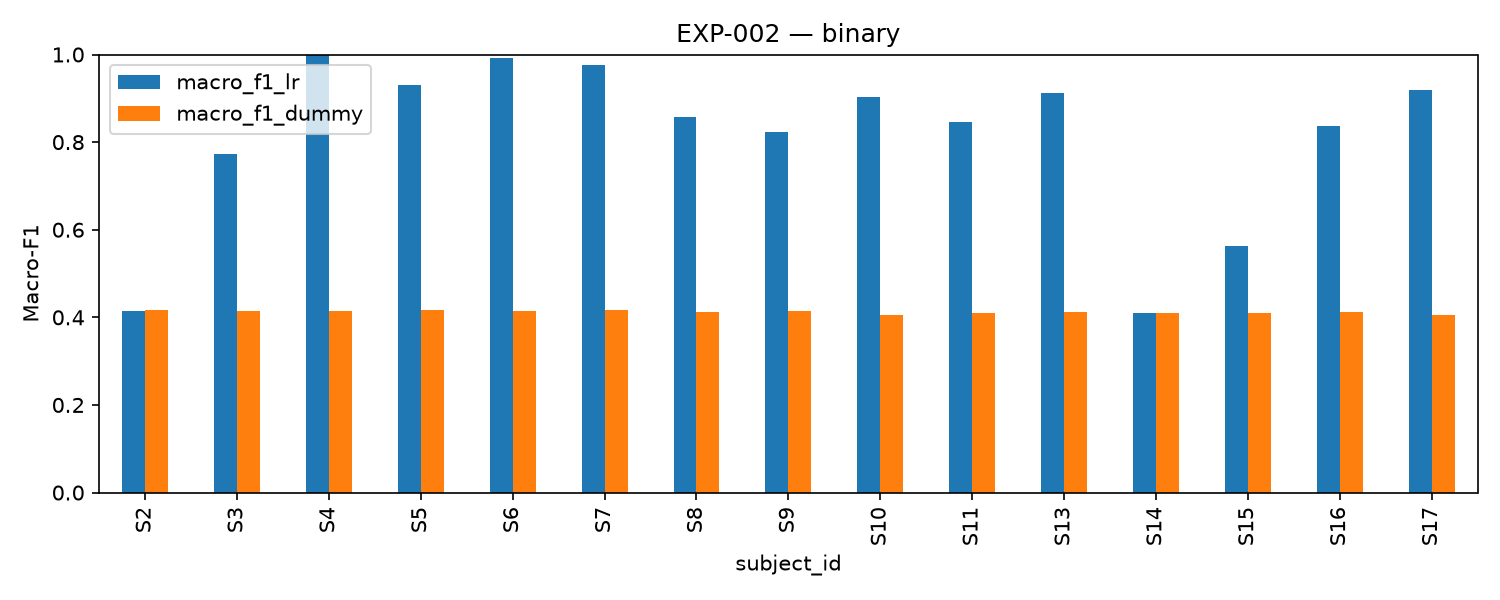

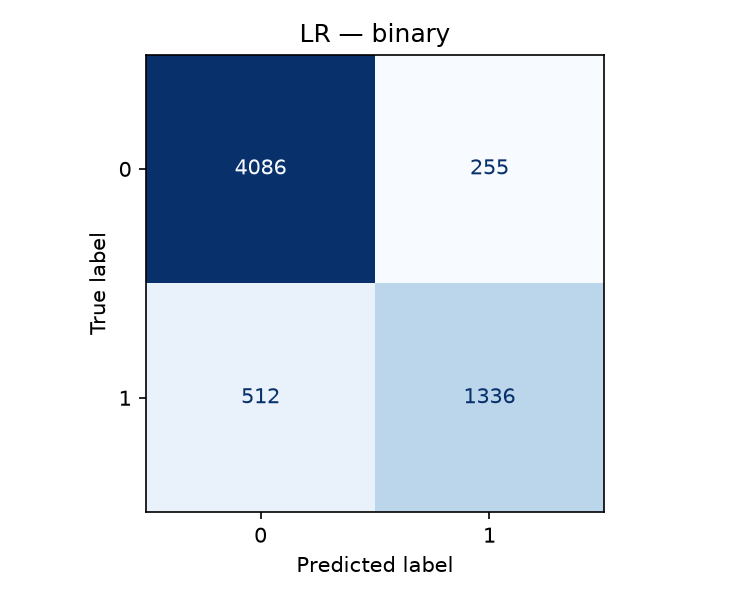

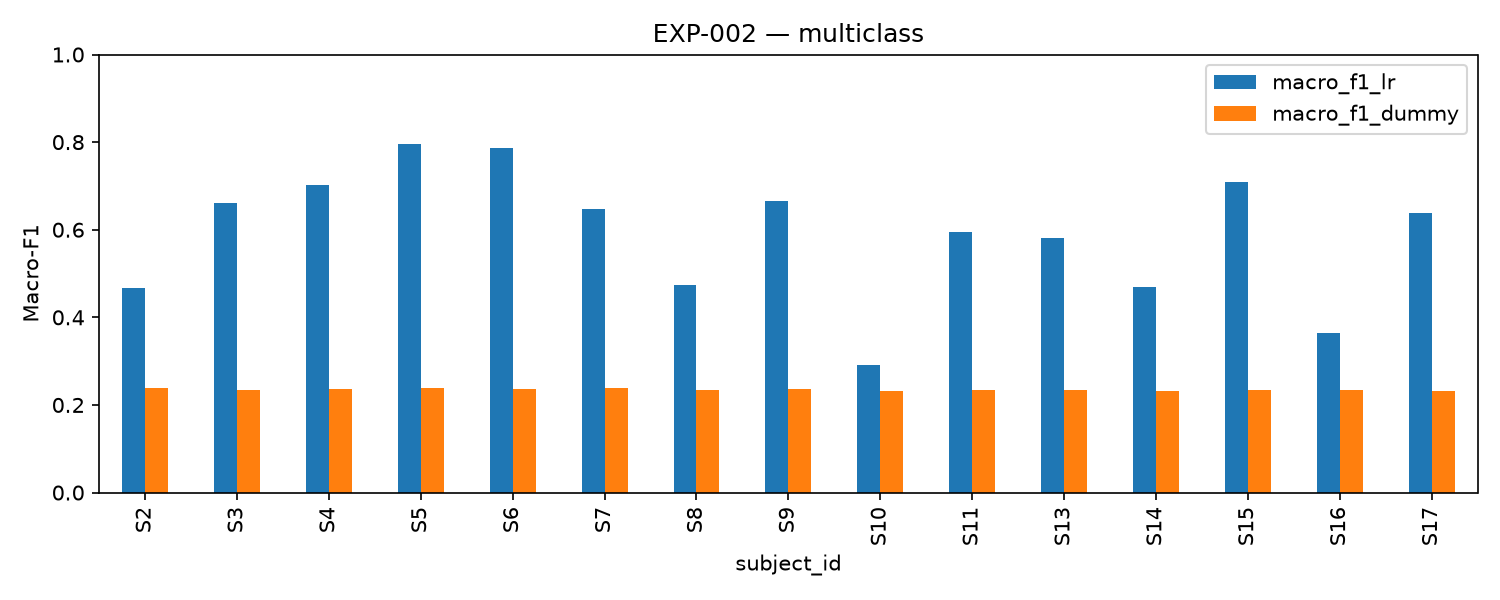

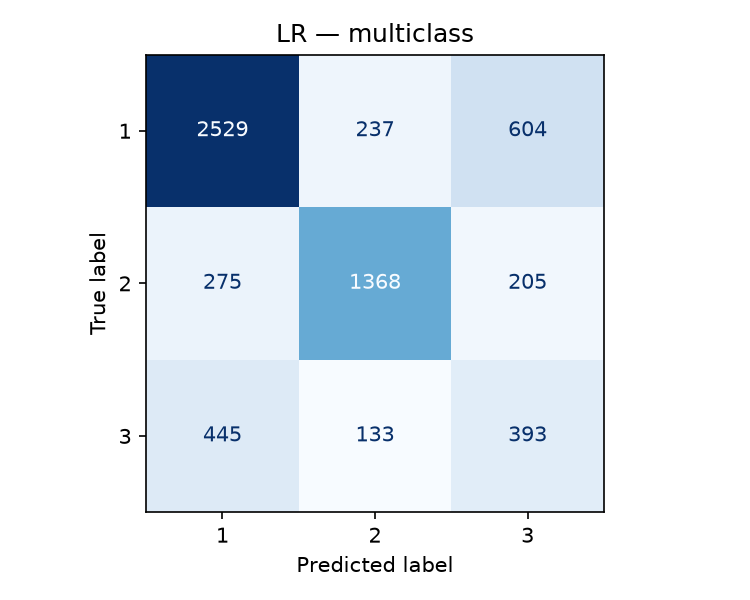

In [7]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

FIGURES = RUN_DIR_R02 / "figures"
FIGURES.mkdir(exist_ok=True)
predictions = pd.read_csv(RUN_DIR_R02 / "predictions.csv")
assert len(predictions) == 2 * len(df)
assert not predictions.duplicated(["task", "model", "subject_id", "window_id"]).any()
for task in ["binary", "multiclass"]:
    part = comparison.loc[comparison.task.eq(task)].set_index("subject_id").reindex(SUBJECTS)
    ax = part[["macro_f1_lr", "macro_f1_dummy"]].plot.bar(figsize=(10, 4), ylim=(0, 1))
    ax.set_title(f"EXP-002 — {task}")
    ax.set_ylabel("Macro-F1")
    plt.tight_layout()
    plt.savefig(FIGURES / f"{task}_macro_f1.png", dpi=150)
    display(Image(filename=str(FIGURES / f"{task}_macro_f1.png")))
    plt.close()
    pred = predictions.loc[predictions.task.eq(task)]
    labels = [0, 1] if task == "binary" else [1, 2, 3]
    cm = confusion_matrix(pred.y_true, pred.y_pred, labels=labels)
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"LR — {task}")
    fig.tight_layout()
    fig.savefig(FIGURES / f"{task}_confusion_matrix.png", dpi=150)
    display(Image(filename=str(FIGURES / f"{task}_confusion_matrix.png")))
    plt.close(fig)


In [8]:
for task, part in metrics_r02.groupby("task"):
    print(task)
    for metric in ["macro_f1", "balanced_accuracy"]:
        print(f"{metric}: {part[metric].mean():.6f} ± {part[metric].std():.6f}")
    best = part.loc[part.macro_f1.idxmax()]
    worst = part.loc[part.macro_f1.idxmin()]
    print(f"Macro-F1 cao nhất: {best.subject_id} ({best.macro_f1:.6f})")
    print(f"Macro-F1 thấp nhất: {worst.subject_id} ({worst.macro_f1:.6f})")


binary
macro_f1: 0.810269 ± 0.193757
balanced_accuracy: 0.830362 ± 0.175180
Macro-F1 cao nhất: S4 (1.000000)
Macro-F1 thấp nhất: S14 (0.409222)
multiclass
macro_f1: 0.589391 ± 0.148416
balanced_accuracy: 0.631471 ± 0.139367
Macro-F1 cao nhất: S5 (0.796091)
Macro-F1 thấp nhất: S10 (0.290313)


## Kết quả và nhận xét R02

Đã hoàn thành LOSO 15 người cho hai bài toán, tổng cộng 30 fold.

- binary: Macro-F1 = 0.810269 ± 0.193757; Balanced Accuracy = 0.830362 ± 0.175180.
  Macro-F1 cao nhất ở S4 (1.000000), thấp nhất ở S14 (0.409222).
  So với Dummy: Macro-F1 trung bình thay đổi +0.397988; tăng ở 13 người, giảm ở 1 người.
- multiclass: Macro-F1 = 0.589391 ± 0.148416; Balanced Accuracy = 0.631471 ± 0.139367.
  Macro-F1 cao nhất ở S5 (0.796091), thấp nhất ở S10 (0.290313).
  So với Dummy: Macro-F1 trung bình thay đổi +0.354344; tăng ở 15 người, giảm ở 0 người.

Ghi nhận 0 cảnh báo trong R02.
Điểm trung bình và độ lệch chuẩn được tính theo người, mỗi người có trọng số bằng nhau.
Confusion matrix gộp các cửa sổ dự đoán ngoài mẫu nên có trọng số khác bảng trung bình theo người.

LR có thể cải thiện điểm trung bình nhưng chưa ổn định trên mọi người. Không chọn tham số dựa trên điểm outer test.

## Giới hạn

Chưa tuning, chưa cân bằng lớp và chưa kiểm định ý nghĩa thống kê. Kết quả trên WESAD chưa chứng minh hiệu quả ngoài thực tế.

## Quyết định tiếp theo

Thực hiện EXP-011 với class_weight=balanced, giữ nguyên dữ liệu, preprocessing, cách chia fold và tham số LR còn lại để kiểm tra tác động của cân bằng lớp.